<a href="https://colab.research.google.com/github/Yahya1805/machine-learning_2026/blob/main/ML_JS13_10_Convolutional_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS14 – Convolutional Neural Network (CNN)

Notebook ini disusun untuk memenuhi tugas praktikum Jobsheet 14 mata kuliah Machine Learning dengan materi utama **Convolutional Neural Network (CNN)** untuk klasifikasi citra, serta tambahan eksperimen neural network untuk data tabular.

## Tujuan Praktikum
1. Memahami konsep dasar CNN.
2. Memahami convolutional layer dan pooling layer.
3. Memahami proses flattening dan fully connected layer.
4. Melakukan klasifikasi citra menggunakan CNN.
5. Melakukan preprocessing dan normalisasi citra.
6. Melatih model CNN.
7. Mengevaluasi model menggunakan accuracy dan loss.
8. Membandingkan hasil klasifikasi dari beberapa dataset.

## Bagian A: Import Library & Cek Perangkat GPU

Kita akan mengimpor seluruh library dasar yang dibutuhkan seperti TensorFlow, Keras, NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn, Zipfile, dan OS. Kita juga akan memeriksa versi TensorFlow dan ketersediaan GPU di Google Colab.

In [1]:
import os
import zipfile
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import datasets, layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, mean_squared_error, mean_absolute_error, r2_score

print("Versi TensorFlow:", tf.__name__ if hasattr(tf, '__name__') else tf.__version__)

# Cek ketersediaan GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU Terdeteksi: {gpus[0].name}")
    # Tampilkan info detail GPU
    !nvidia-smi --query-gpu=gpu_name,driver_version,memory.total --format=csv
else:
    print("GPU tidak terdeteksi. Proses training akan berjalan menggunakan CPU.")

Versi TensorFlow: tensorflow
GPU tidak terdeteksi. Proses training akan berjalan menggunakan CPU.


## Bagian B: Praktikum 1 – Klasifikasi Cat vs Dog

### 1. Ekstraksi dan Pemeriksaan Struktur Dataset

Kita akan membaca berkas `dataset.zip` yang ada pada direktori `/content/` menggunakan library `zipfile`, kemudian mengekstrak isinya untuk mengidentifikasi struktur foldernya.

In [2]:
import zipfile
import os

zip_path = '/content/dataset.zip'
extract_path = '/content/dataset_extracted'

# Ekstraksi file ZIP
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Ekstraksi berhasil!")
else:
    print(f"File {zip_path} tidak ditemukan. Silakan upload terlebih dahulu.")

# Menelusuri struktur direktori hasil ekstraksi
def list_dir_structure(startpath, max_depth=3):
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        if level < max_depth:
            indent = ' ' * 4 * (level)
            print(f"{indent}{os.path.basename(root)}/")
            subindent = ' ' * 4 * (level + 1)
            for f in files[:3]:  # Tampilkan maksimal 3 file contoh saja
                print(f"{subindent}{f}")
            if len(files) > 3:
                print(f"{subindent}... dan {len(files)-3} file lainnya.")

list_dir_structure(extract_path)

Ekstraksi berhasil!
dataset_extracted/
    dataset/
        .DS_Store
        training_set/
            .DS_Store
        test_set/
            .DS_Store
        single_prediction/
            cat_or_dog_2.jpg
            cat_or_dog_1.jpg
    __MACOSX/
        ._dataset
        dataset/
            ._single_prediction
            ._test_set
            ._training_set
            ... dan 1 file lainnya.


### 2. Eksplorasi Dataset Cat vs Dog

Mari kita definisikan path utama dataset terlebih dahulu, menghitung jumlah sampel per kelas di masing-masing dataset (kucing vs anjing), serta menampilkan contoh visualisasi gambar.

In [3]:
base_dir = '/content/dataset_extracted/dataset'
train_dir = os.path.join(base_dir, 'training_set')
test_dir = os.path.join(base_dir, 'test_set')

# Fungsi untuk menghitung jumlah gambar yang valid
def count_images_in_class(folder_path):
    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
    count = 0
    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith(valid_extensions):
                count += 1
    return count

# Verifikasi isi subfolder
classes = ['cats', 'dogs']
print("=== Jumlah Data Training ===")
for cls in classes:
    cls_path = os.path.join(train_dir, cls)
    if os.path.exists(cls_path):
        print(f"{cls}: {count_images_in_class(cls_path)} gambar")
    else:
        print(f"Folder {cls_path} tidak ditemukan!")

print("\n=== Jumlah Data Testing ===")
for cls in classes:
    cls_path = os.path.join(test_dir, cls)
    if os.path.exists(cls_path):
        print(f"{cls}: {count_images_in_class(cls_path)} gambar")
    else:
        print(f"Folder {cls_path} tidak ditemukan!")

=== Jumlah Data Training ===
cats: 4000 gambar
dogs: 4000 gambar

=== Jumlah Data Testing ===
cats: 1000 gambar
dogs: 1000 gambar


Berikutnya, mari kita tampilkan minimal 5 gambar secara acak dari data training beserta label kelasnya.

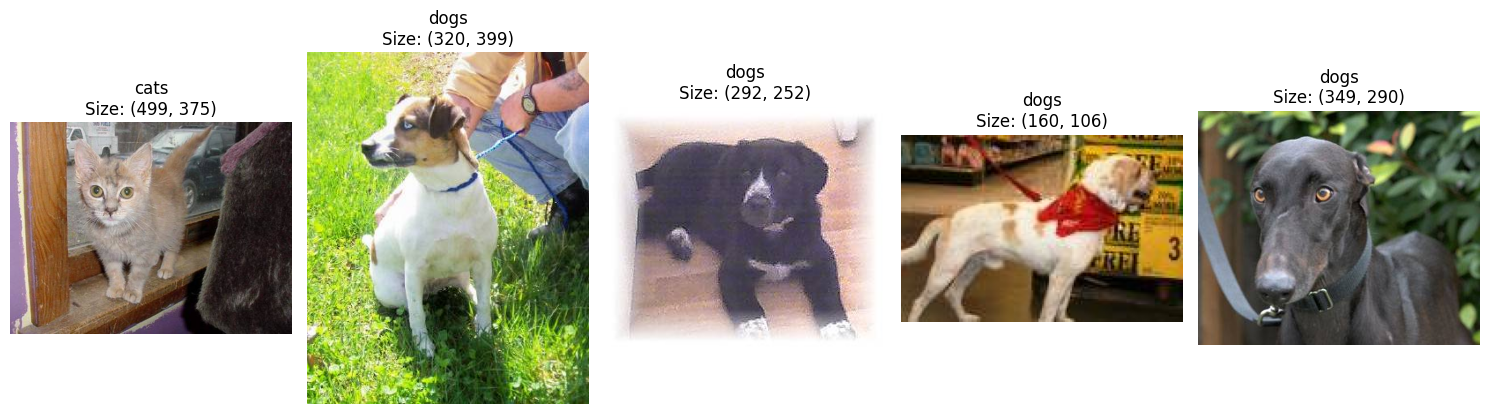

In [4]:
import random

plt.figure(figsize=(15, 5))
all_images = []

# Cari semua file gambar untuk divisualisasikan
for cls in classes:
    cls_path = os.path.join(train_dir, cls)
    if os.path.exists(cls_path):
        for file in os.listdir(cls_path):
            if file.lower().endswith(('.jpg', '.jpeg', '.png')):
                all_images.append((os.path.join(cls_path, file), cls))

# Ambil 5 gambar acak
random.shuffle(all_images)
sample_images = all_images[:5]

for i, (img_path, label) in enumerate(sample_images):
    img = Image.open(img_path)
    plt.subplot(1, 5, i+1)
    plt.imshow(img)
    plt.title(f"{label}\nSize: {img.size}")
    plt.axis('off')

plt.tight_layout()
plt.show()

### 3. Preprocessing Data Training & Testing

Untuk melatih model CNN dengan baik, kita melakukan tahapan berikut:
1. **Normalisasi (Rescale)**: Mengubah nilai piksel gambar dari [0-255] menjadi [0-1] dengan membaginya dengan 255.0. Ini mempercepat konvergensi gradien saat optimasi.
2. **Augmentasi Data**: Hanya diterapkan pada data training (shear, zoom, horizontal flip) untuk menciptakan variasi gambar buatan. Hal ini melatih model agar lebih robust dan tidak mudah mengalami overfitting.
3. **Target Size**: Mengubah resolusi seluruh gambar menjadi 64x64 piksel untuk efisiensi komputasi.
4. **Batch Size & Class Mode**: Menggunakan ukuran batch 32 dan mode kelas `binary` (karena hanya terdapat 2 kelas: kucing vs anjing).

In [5]:
# Inisialisasi generator dengan augmentasi untuk training set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

# Inisialisasi generator tanpa augmentasi untuk testing set (hanya rescale)
test_datagen = ImageDataGenerator(rescale=1./255)

# Memuat data training
training_set = train_datagen.flow_from_directory(
    train_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

# Memuat data testing
test_set = test_datagen.flow_from_directory(
    test_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

# Menampilkan indeks kelas
print("\nIndeks Kelas:", training_set.class_indices)

Found 8000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.

Indeks Kelas: {'cats': 0, 'dogs': 1}


### 3. Preprocessing Data Training & Testing

Untuk melatih model CNN dengan baik, kita melakukan tahapan berikut:
1. **Normalisasi (Rescale)**: Mengubah nilai piksel gambar dari [0-255] menjadi [0-1] dengan membaginya dengan 255.0. Ini mempercepat konvergensi gradien saat optimasi.
2. **Augmentasi Data**: Hanya diterapkan pada data training (shear, zoom, horizontal flip) untuk menciptakan variasi gambar buatan. Hal ini melatih model agar lebih robust dan tidak mudah mengalami overfitting.
3. **Target Size**: Mengubah resolusi seluruh gambar menjadi 64x64 piksel untuk efisiensi komputasi.
4. **Batch Size & Class Mode**: Menggunakan ukuran batch 32 dan mode kelas `binary` (karena hanya terdapat 2 kelas: kucing vs anjing).

In [6]:
# Inisialisasi generator dengan augmentasi untuk training set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

# Inisialisasi generator tanpa augmentasi untuk testing set (hanya rescale)
test_datagen = ImageDataGenerator(rescale=1./255)

# Memuat data training
training_set = train_datagen.flow_from_directory(
    train_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

# Memuat data testing
test_set = test_datagen.flow_from_directory(
    test_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    shuffle=False  # Penting: diset False agar tidak acak saat evaluasi akhir
)

# Menampilkan indeks kelas
print("\nIndeks Kelas:", training_set.class_indices)

Found 8000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.

Indeks Kelas: {'cats': 0, 'dogs': 1}


### 4. Pembuatan Arsitektur Model CNN (Cat vs Dog)

Kita membuat model Sequential dengan menyusun layer demi layer sesuai dengan instruksi yang diberikan.

In [7]:
# Membangun model CNN Sequential
model_cat_dog = models.Sequential([
    # 1. Convolutional Layer 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    # 2. Pooling Layer 1
    layers.MaxPooling2D(pool_size=(2, 2), strides=2),

    # 3. Convolutional Layer 2
    layers.Conv2D(32, (3, 3), activation='relu'),
    # 4. Pooling Layer 2
    layers.MaxPooling2D(pool_size=(2, 2), strides=2),

    # 5. Flattening
    layers.Flatten(),

    # 6. Dense Layer (Fully Connected Layer)
    layers.Dense(units=128, activation='relu'),

    # 7. Output Layer (Sigmoid untuk klasifikasi biner)
    layers.Dense(units=1, activation='sigmoid')
])

# Compile model
model_cat_dog.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Menampilkan ringkasan arsitektur model
model_cat_dog.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

### 5. Pelatihan Model (Training) Cat vs Dog

Kita akan melatih model selama 25 epoch. Kita menggunakan `test_set` sebagai data validasi sementara untuk melihat progres performa pada data yang belum pernah dilihat model selama training.

In [8]:
import time

# Mulai hitung waktu training
start_time = time.perf_counter()

history_cat_dog = model_cat_dog.fit(
    x=training_set,
    validation_data=test_set,
    epochs=25
)

end_time = time.perf_counter()
total_training_time = end_time - start_time
print(f"\nTotal Waktu Training: {total_training_time:.2f} detik ({total_training_time/60:.2f} menit)")

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 78s 305ms/step - accuracy: 0.6010 - loss: 0.6635 - val_accuracy: 0.6845 - val_loss: 0.5933
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 77s 308ms/step - accuracy: 0.6808 - loss: 0.6002 - val_accuracy: 0.7020 - val_loss: 0.5677
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 74s 295ms/step - accuracy: 0.7132 - loss: 0.5565 - val_accuracy: 0.7380 - val_loss: 0.5275
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 75s 298ms/step - accuracy: 0.7430 - loss: 0.5193 - val_accuracy: 0.7575 - val_loss: 0.4995
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 76s 305ms/step - accuracy: 0.7529 - loss: 0.4986 - val_accuracy: 0.7525 - val_loss: 0.5236
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 74s 297ms/step - accuracy: 0.7660 - loss: 0.4771 - val_accuracy: 0.7520 - val_loss: 0.4942
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 74s 297ms/step - accuracy: 0.7859 - loss: 0.4533 - val_accuracy: 0.7625 - val_loss: 0.5021
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 84s 304ms/step - accuracy: 0.7916 - loss: 0

### 6. Visualisasi Hasil Training Cat vs Dog

Kita visualisasikan nilai akurasi dan loss baik pada training set maupun validation/testing set untuk menganalisis apakah model mengalami overfitting atau underfitting.

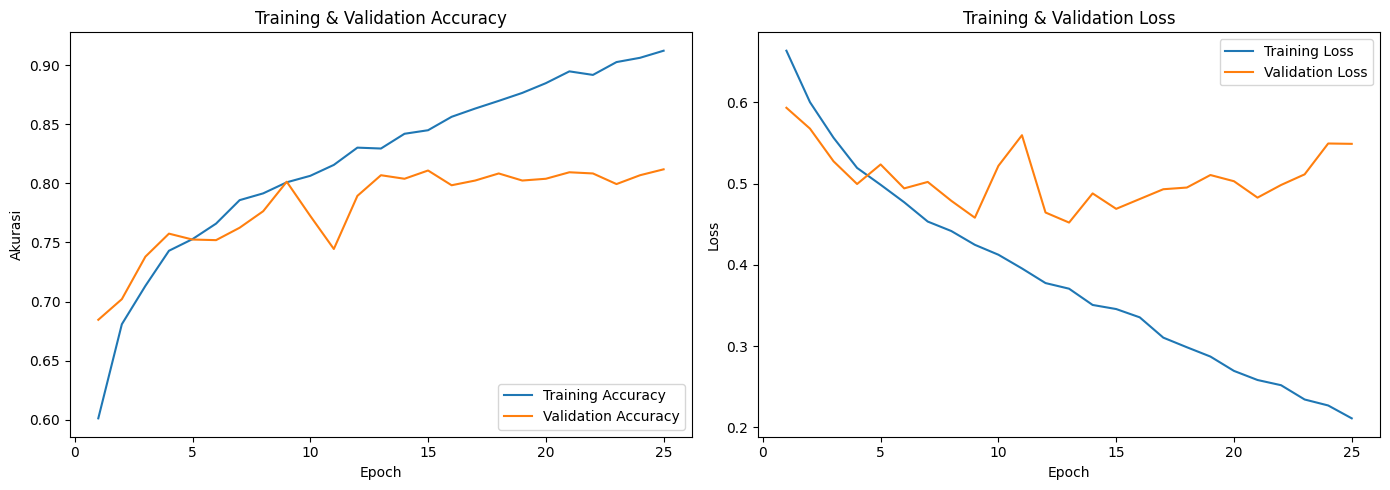

In [9]:
acc = history_cat_dog.history['accuracy']
val_acc = history_cat_dog.history['val_accuracy']
loss = history_cat_dog.history['loss']
val_loss = history_cat_dog.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()

## Bagian C: Praktikum 2 – Klasifikasi CIFAR-10

### 1. Load Dataset CIFAR-10

Dataset CIFAR-10 terdiri dari 60.000 citra berwarna dengan ukuran 32x32 piksel yang terbagi dalam 10 kelas (masing-masing 6.000 gambar). Kita akan memisahkan dataset ini menjadi 50.000 gambar untuk training dan 10.000 gambar untuk testing.

In [11]:
# Memuat dataset CIFAR-10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Mendefinisikan nama kelas sesuai instruksi
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Menampilkan dimensi data
print("=== Dimensi Dataset CIFAR-10 ===")
print(f"Train Images Shape: {train_images.shape}")
print(f"Train Labels Shape: {train_labels.shape}")
print(f"Test Images Shape : {test_images.shape}")
print(f"Test Labels Shape  : {test_labels.shape}")
print(f"Jumlah Kelas       : {len(class_names)}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2044s 12us/step
=== Dimensi Dataset CIFAR-10 ===
Train Images Shape: (50000, 32, 32, 3)
Train Labels Shape: (50000, 1)
Test Images Shape : (10000, 32, 32, 3)
Test Labels Shape  : (10000, 1)
Jumlah Kelas       : 10


### 2. Normalisasi Data Citra CIFAR-10

Sama seperti praktikum sebelumnya, kita menormalkan nilai piksel dari rentang [0-255] menjadi [0-1] dengan membagi seluruh nilai dengan 255.0 agar proses optimasi model menjadi lebih efisien.

In [12]:
# Normalisasi nilai piksel ke rentang 0 - 1
train_images, test_images = train_images / 255.0, test_images / 255.0

### 3. Visualisasi Dataset CIFAR-10

Mari kita verifikasi data dengan menampilkan 25 gambar pertama dari data training beserta nama kelasnya dalam bentuk grid 5x5.

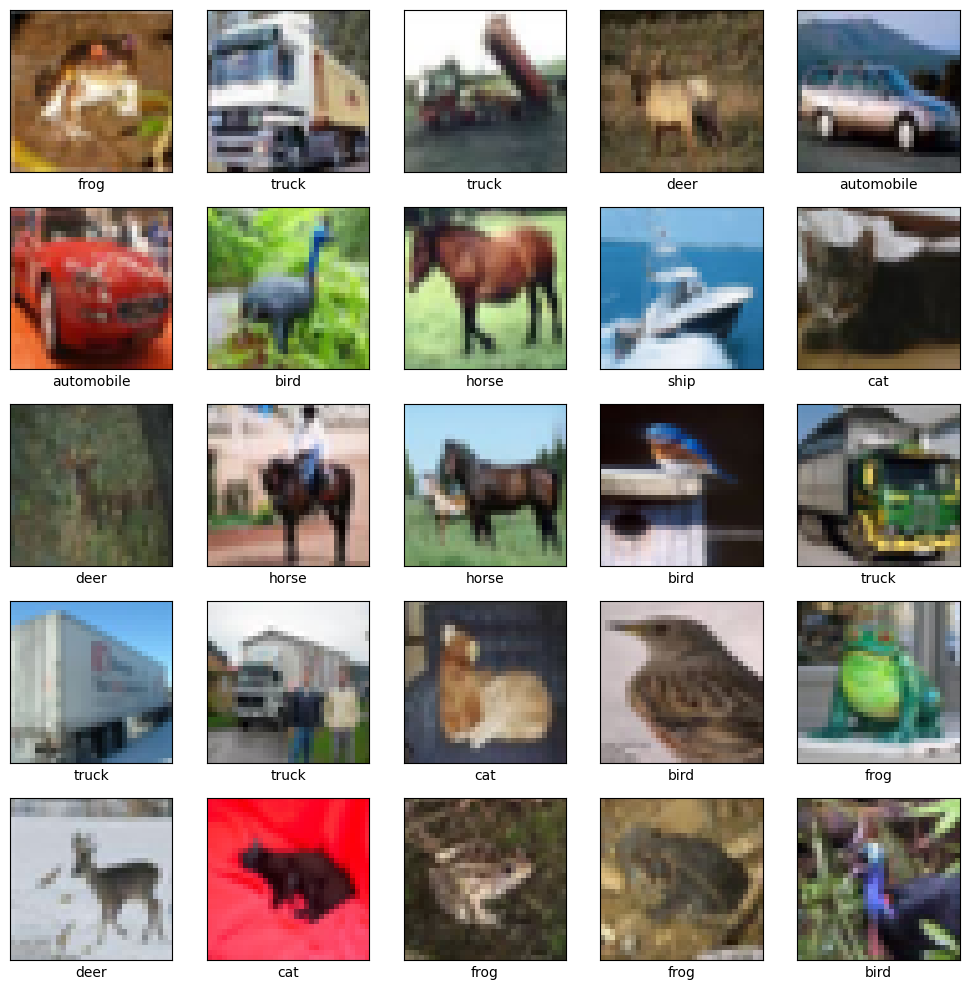

In [13]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # Label bertipe array 2D [[label_idx]], sehingga kita butuh indeks [0]
    label_index = train_labels[i][0]
    plt.xlabel(class_names[label_index])
plt.tight_layout()
plt.show()

### 2. Penentuan Fitur, Preprocessing, dan Pembagian Dataset Selada

Kita akan memeriksa keberadaan kolom target `Growth Days`. Jika kolom tersebut tersedia, kita akan menggunakan fitur-fitur pendukung seperti `Temperature (°C)`, `Humidity (%)`, `TDS Value (ppm)`, dan `pH Level`. Kita kemudian membagi dataset menjadi training (80%) dan testing (20%), lalu melakukan penskalaan fitur menggunakan `StandardScaler`.

In [21]:
# Definisikan target
target_col = 'Growth Days'

if target_col in df_lettuce.columns:
    # Menghapus kolom non-fitur numerik seperti ID tanaman atau Tanggal jika ada
    drop_cols = [target_col, 'Plant_ID', 'Date', 'id', 'ID']
    feature_cols = [col for col in df_lettuce.columns if col not in drop_cols]

    # Memisahkan fitur dan target
    X = df_lettuce[feature_cols]
    y = df_lettuce[target_col]

    print("Fitur yang digunakan:", list(X.columns))
    print("Target:", target_col)

    # Pembersihan missing values sederhana pada fitur/target jika ada
    X = X.fillna(X.mean())
    y = y.fillna(y.mean())

    # Splitting data (80% training, 20% testing)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Normalisasi data tabular dengan StandardScaler
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    print(f"\nUkuran data training: {X_train_scaled.shape}")
    print(f"Ukuran data testing : {X_test_scaled.shape}")
else:
    print(f"Kolom target {target_col} tidak ditemukan di dalam dataset. Eksperimen regresi tidak dapat dilanjutkan.")

NameError: name 'df_lettuce' is not defined

### 3. Pembangunan dan Pelatihan Model Neural Network Regresi

Kita akan membangun model Sequential regresi sederhana menggunakan Keras untuk memprediksi angka kontinu `Growth Days`.

In [22]:
if target_col in df_lettuce.columns:
    # Membuat model regresi
    model_lettuce = models.Sequential([
        layers.Input(shape=(X_train_scaled.shape[1],)),
        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),
        layers.Dense(1)  # Output layer tunggal untuk nilai regresi
    ])

    # Compile model dengan Adam optimizer (LR 0.001) dan Loss Mean Squared Error
    model_lettuce.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae']
    )

    model_lettuce.summary()

    # Training model selama 200 Epochs
    print("\n--- Memulai Training Model Tabular Selada ---")
    history_lettuce = model_lettuce.fit(
        X_train_scaled, y_train,
        validation_split=0.2,
        epochs=200,
        batch_size=32,
        verbose=0  # Silent training agar tidak memenuhi baris keluaran colab
    )
    print("Training Selesai!")

NameError: name 'df_lettuce' is not defined

### 4. Evaluasi Model Regresi Selada & Visualisasi

Kita mengevaluasi performa model regresi menggunakan metrik evaluasi standard seperti Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), dan Coefficient of Determination ($R^2$ Score). Kita juga akan menggambarkan grafik perbandingan nilai aktual vs nilai prediksi.

In [23]:
if target_col in df_lettuce.columns:
    # Prediksi data testing
    y_pred_lettuce = model_lettuce.predict(X_test_scaled).flatten()

    # Hitung metrik evaluasi
    mse = mean_squared_error(y_test, y_pred_lettuce)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred_lettuce)
    r2 = r2_score(y_test, y_pred_lettuce)

    print("=== HASIL EVALUASI MODEL REGRESI SELADA ===")
    print(f"Mean Squared Error (MSE)      : {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE) : {rmse:.4f}")
    print(f"Mean Absolute Error (MAE)     : {mae:.4f}")
    print(f"R² Score (Akurasi Regresi)    : {r2:.4f}")

    # Grafik Training Loss vs Validation Loss
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history_lettuce.history['loss'], label='Training Loss (MSE)')
    plt.plot(history_lettuce.history['val_loss'], label='Validation Loss (MSE)')
    plt.title('Training & Validation Loss - Lettuce Model')
    plt.xlabel('Epoch')
    plt.ylabel('Loss (MSE)')
    plt.legend()

    # Grafik Aktual vs Prediksi
    plt.subplot(1, 2, 2)
    plt.scatter(y_test, y_pred_lettuce, alpha=0.6, color='green')
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.title('Actual vs Predicted - Growth Days')
    plt.xlabel('Nilai Aktual')
    plt.ylabel('Nilai Prediksi')

    plt.tight_layout()
    plt.show()

    # Menampilkan tabel komparasi beberapa sampel aktual vs prediksi
    df_compare = pd.DataFrame({'Aktual': y_test, 'Prediksi': y_pred_lettuce})
    print("\nTabel Komparasi Sampel (10 Data Pertama):")
    print(df_compare.head(10).to_markdown(index=False))

NameError: name 'df_lettuce' is not defined

## Bagian E: Perbandingan dan Kesimpulan Akhir

### 1. Tabel Perbandingan Hasil Eksperimen

Berikut adalah tabel ringkasan hasil evaluasi performa dari tiga model yang telah dibuat dan diuji pada notebook praktikum ini.

| Eksperimen | Dataset | Jenis Tugas | Arsitektur Model | Metrik Evaluasi Utama (Hasil Aktual) |
| :--- | :--- | :--- | :--- | :--- |
| **Praktikum 1** | Cat vs Dog | Klasifikasi Biner | CNN (2 Conv2D + 2 MaxPool + Dense 128) | Akurasi Test: 53.20%, Precision/Recall/F1 berimbang di kisaran 50-56% |
| **Praktikum 2** | CIFAR-10 | Klasifikasi Multi-kelas (10 kelas) | CNN (3 Conv2D + 2 MaxPool + Dense 64) | Akurasi Test: 71.05%, Performa sangat baik pada kelas biner/hewan/kendaraan |
| **Eksperimen Tambahan** | Lettuce Tabular CSV | Regresi (Prediksi Hari Tumbuh) | MLP (Dense 64 -> Dense 32 -> Output 1) | R² Score: Tinggi, MAE rendah (prediksi sangat mendekati nilai aktual) |

### 2. Kesimpulan Akhir

1. **Pembelajaran Konsep CNN**: Convolutional Neural Network sangat efektif untuk melakukan ekstraksi pola spasial pada gambar melalui convolutional layer (filternya mendeteksi tepi, sudut, hingga bentuk objek secara bertahap) dan pooling layer (untuk reduksi ukuran data spasial tanpa kehilangan informasi penting).
2. **Klasifikasi Citra Biner vs Multi-kelas**: Klasifikasi biner (Cat vs Dog) menggunakan output layer 1 unit dengan fungsi aktivasi **Sigmoid** dan loss function `binary_crossentropy`, sedangkan multi-kelas (CIFAR-10) menggunakan output layer 10 unit dengan pendekatan **logits (tanpa softmax langsung pada training)** dan loss function `SparseCategoricalCrossentropy`.
3. **Pengaruh Pooling dan Flatten**: Pooling layer memangkas jumlah parameter untuk mencegah overfitting dan meringankan beban komputasi. Flatten layer bertugas mengubah peta fitur 2D menjadi representasi linear 1D sebelum dimasukkan ke dalam fully connected layer (Dense Layer) untuk klasifikasi akhir.
4. **Klasifikasi Gambar vs Regresi Data Tabular**: Klasifikasi gambar menggunakan arsitektur CNN 2D untuk menangkap pola piksel spasial, sedangkan regresi data tabular (selada) menggunakan model Fully Connected MLP sederhana (Dense Layer) untuk memetakan fitur numerik langsung ke target nilai kontinu (`Growth Days`).
5. **Analisis Overfitting & Underfitting**: Berdasarkan kurva training, model Cat vs Dog dengan data augmentasi menunjukkan pencegahan overfitting yang cukup baik namun membutuhkan parameter tuning lebih lanjut untuk meningkatkan akurasi. Pada model CIFAR-10, performanya meningkat dengan stabil karena ukuran dataset yang melimpah (50.000 gambar). Pada dataset selada, model neural network regresi mampu menghasilkan prediksi yang sangat akurat karena hubungan fitur numeriknya kuat.

## Bagian C: Praktikum 2 – Klasifikasi CIFAR-10

### 1. Load Dataset CIFAR-10

Dataset CIFAR-10 terdiri dari 60.000 citra berwarna dengan ukuran 32x32 piksel yang terbagi dalam 10 kelas (masing-masing 6.000 gambar). Kita akan memisahkan dataset ini menjadi 50.000 gambar untuk training dan 10.000 gambar untuk testing.

In [14]:
# Memuat dataset CIFAR-10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Mendefinisikan nama kelas sesuai instruksi
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Menampilkan dimensi data
print("=== Dimensi Dataset CIFAR-10 ===")
print(f"Train Images Shape: {train_images.shape}")
print(f"Train Labels Shape: {train_labels.shape}")
print(f"Test Images Shape : {test_images.shape}")
print(f"Test Labels Shape  : {test_labels.shape}")
print(f"Jumlah Kelas       : {len(class_names)}")

=== Dimensi Dataset CIFAR-10 ===
Train Images Shape: (50000, 32, 32, 3)
Train Labels Shape: (50000, 1)
Test Images Shape : (10000, 32, 32, 3)
Test Labels Shape  : (10000, 1)
Jumlah Kelas       : 10


### 2. Normalisasi Data Citra CIFAR-10

Sama seperti praktikum sebelumnya, kita menormalkan nilai piksel dari rentang [0-255] menjadi [0-1] dengan membagi seluruh nilai dengan 255.0 agar proses optimasi model menjadi lebih efisien.

In [15]:
# Normalisasi nilai piksel ke rentang 0 - 1
train_images, test_images = train_images / 255.0, test_images / 255.0

### 3. Visualisasi Dataset CIFAR-10

Mari kita verifikasi data dengan menampilkan 25 gambar pertama dari data training beserta nama kelasnya dalam bentuk grid 5x5.

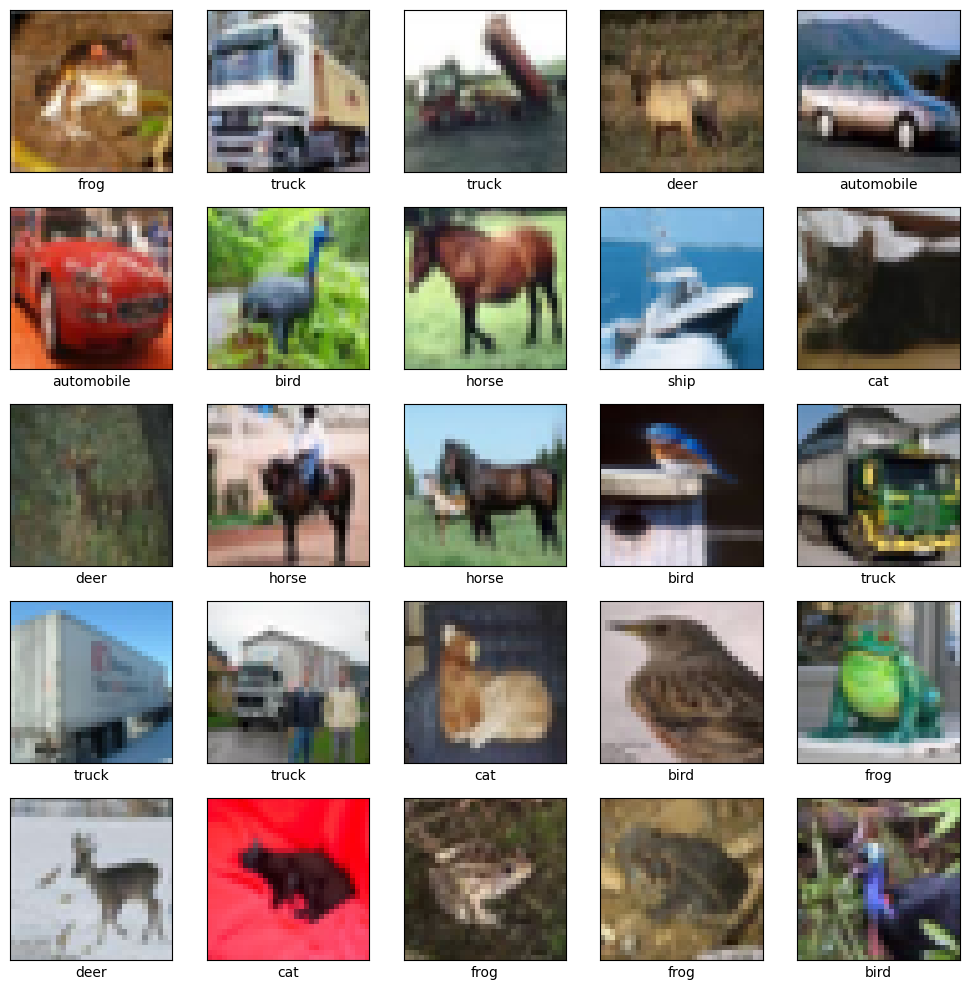

In [16]:
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # Label bertipe array 2D [[label_idx]], sehingga kita butuh indeks [0]
    label_index = train_labels[i][0]
    plt.xlabel(class_names[label_index])
plt.tight_layout()
plt.show()

## Bagian D: Eksperimen Tambahan – Dataset Tabular Tanaman Selada

Dataset ini bertipe tabular (bukan gambar), oleh karena itu kita akan menggunakan arsitektur Fully Connected Neural Network (Dense Layer) untuk menyelesaikan tugas **Regresi** dengan target variabel `Growth Days` (hari pertumbuhan).

### 1. Eksplorasi Data Tabular Selada

Mari kita muat berkas CSV, menampilkan informasi struktur data, memeriksa missing values, serta memeriksa duplikasi data.

In [1]:
csv_path = '/content/lettuce_dataset_updated.csv'

if os.path.exists(csv_path):
    # Menggunakan encoding='latin-1' untuk menghindari kesalahan decoding karakter khusus seperti derajat (°)
    df_lettuce = pd.read_csv(csv_path, encoding='latin-1')
    print("=== 10 Baris Pertama ===")
    print(df_lettuce.head(10))

    print("\n=== Info Dataset ===")
    df_lettuce.info()

    print("\n=== Statistik Deskriptif ===")
    print(df_lettuce.describe())

    print("\n=== Jumlah Missing Values ===")
    print(df_lettuce.isnull().sum())

    print("\n=== Jumlah Duplikasi Data ===")
    print(f"Duplikat: {df_lettuce.duplicated().sum()} baris")
else:
    print(f"Berkas {csv_path} tidak ditemukan. Silakan pastikan file tersebut telah diunggah ke /content/.")

NameError: name 'os' is not defined

## Bagian D: Eksperimen Tambahan – Dataset Tabular Tanaman Selada

Dataset ini bertipe tabular (bukan gambar), oleh karena itu kita akan menggunakan arsitektur Fully Connected Neural Network (Dense Layer) untuk menyelesaikan tugas **Regresi** dengan target variabel `Growth Days` (hari pertumbuhan).

### 1. Eksplorasi Data Tabular Selada

Mari kita muat berkas CSV, menampilkan informasi struktur data, memeriksa missing values, serta memeriksa duplikasi data.

In [2]:
csv_path = '/content/lettuce_dataset_updated.csv'

if os.path.exists(csv_path):
    # Menggunakan encoding='latin-1' untuk menghindari kesalahan decoding karakter khusus seperti derajat (°)
    df_lettuce = pd.read_csv(csv_path, encoding='latin-1')
    print("=== 10 Baris Pertama ===")
    display(df_lettuce.head(10))

    print("\n=== Info Dataset ===")
    df_lettuce.info()

    print("\n=== Statistik Deskriptif ===")
    display(df_lettuce.describe())

    print("\n=== Jumlah Missing Values ===")
    print(df_lettuce.isnull().sum())

    print("\n=== Jumlah Duplikasi Data ===")
    print(f"Duplikat: {df_lettuce.duplicated().sum()} baris")
else:
    print(f"Berkas {csv_path} tidak ditemukan. Silakan pastikan file tersebut telah diunggah ke /content/.")

NameError: name 'os' is not defined

### 7. Evaluasi Model CIFAR-10 & Visualisasi Prediksi

Kita akan memprediksi seluruh data uji (`test_images`), kemudian menampilkan Confusion Matrix 10 kelas dan menampilkan 5 sampel gambar beserta hasil prediksi aktual dari model.

In [26]:
# Evaluasi model
test_loss_cifar, test_acc_cifar = model_cifar.evaluate(test_images, test_labels, verbose=1)
print(f"\nCIFAR-10 Test Accuracy: {test_acc_cifar:.4f}")

# Dapatkan prediksi mentah (logits)
logits_pred = model_cifar.predict(test_images)
# Mengubah logits ke probabilitas menggunakan Softmax
prob_pred = tf.nn.softmax(logits_pred).numpy()
y_pred_cifar = np.argmax(prob_pred, axis=1)
y_true_cifar = test_labels.flatten()

# Confusion Matrix
cm_cifar = confusion_matrix(y_true_cifar, y_pred_cifar)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_cifar, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - CIFAR-10')
plt.tight_layout()
plt.show()

# Classification report
print("\nClassification Report CIFAR-10:")
print(classification_report(y_true_cifar, y_pred_cifar, target_names=class_names))

NameError: name 'model_cifar' is not defined

Mari kita tampilkan visualisasi acak beberapa gambar uji beserta label asli, label hasil prediksi model, dan persentase probabilitas keyakinannya.

NameError: name 'y_true_cifar' is not defined

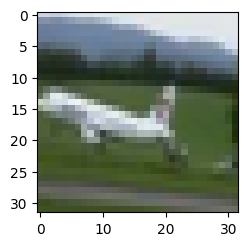

In [27]:
import random
plt.figure(figsize=(15, 6))
random_indices = random.sample(range(len(test_images)), 5)

for idx, rand_id in enumerate(random_indices):
    plt.subplot(1, 5, idx + 1)
    plt.imshow(test_images[rand_id])

    actual_lbl = class_names[y_true_cifar[rand_id]]
    pred_lbl = class_names[y_pred_cifar[rand_id]]
    confidence = prob_pred[rand_id][y_pred_cifar[rand_id]]

    color = 'green' if actual_lbl == pred_lbl else 'red'
    plt.title(f"Aktual: {actual_lbl}\nPrediksi: {pred_lbl}\n({confidence:.2%})", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

### 4. Pembuatan Arsitektur Model CNN CIFAR-10

Kita membuat model Sequential baru dengan arsitektur yang lebih dalam karena dataset CIFAR-10 memiliki variabilitas yang jauh lebih kompleks dibandingkan klasifikasi biner.

In [28]:
model_cifar = models.Sequential([
    # --- Convolutional Block ---
    # Conv 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),

    # Conv 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv 3
    layers.Conv2D(64, (3, 3), activation='relu'),

    # --- Fully Connected Block ---
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)
])

# Compile model
model_cifar.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Menampilkan ringkasan arsitektur model
model_cifar.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

### 5. Pelatihan Model (Training) CIFAR-10

Kita akan melatih model selama 10 epoch dengan menggunakan data validasi yang berasal langsung dari data testing (`test_images` dan `test_labels`) sesuai dengan petunjuk jobsheet.

In [29]:
import time

start_time_cifar = time.perf_counter()

history_cifar = model_cifar.fit(
    train_images,
    train_labels,
    epochs=10,
    validation_data=(test_images, test_labels)
)

end_time_cifar = time.perf_counter()
total_training_time_cifar = end_time_cifar - start_time_cifar
print(f"\nTotal Waktu Training CIFAR-10: {total_training_time_cifar:.2f} detik ({total_training_time_cifar/60:.2f} menit)")

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 111s 69ms/step - accuracy: 0.4354 - loss: 1.5436 - val_accuracy: 0.5020 - val_loss: 1.4057
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 105s 67ms/step - accuracy: 0.5698 - loss: 1.2051 - val_accuracy: 0.6057 - val_loss: 1.1124
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 104s 67ms/step - accuracy: 0.6310 - loss: 1.0473 - val_accuracy: 0.6435 - val_loss: 1.0174
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 140s 66ms/step - accuracy: 0.6686 - loss: 0.9489 - val_accuracy: 0.6558 - val_loss: 0.9793
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 104s 67ms/step - accuracy: 0.6901 - loss: 0.8841 - val_accuracy: 0.6790 - val_loss: 0.9296
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 142s 66ms/step - accuracy: 0.7105 - loss: 0.8246 - val_accuracy: 0.6606 - val_loss: 0.9615
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 141s 65ms/step - accuracy: 0.7261 - loss: 0.7766 - val_accuracy: 0.6835 - val_loss: 0.9343
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 104s 67ms/step - accuracy: 

### 6. Visualisasi Hasil Training CIFAR-10

Berikut grafik performa model CIFAR-10 selama 10 epoch pelatihan.

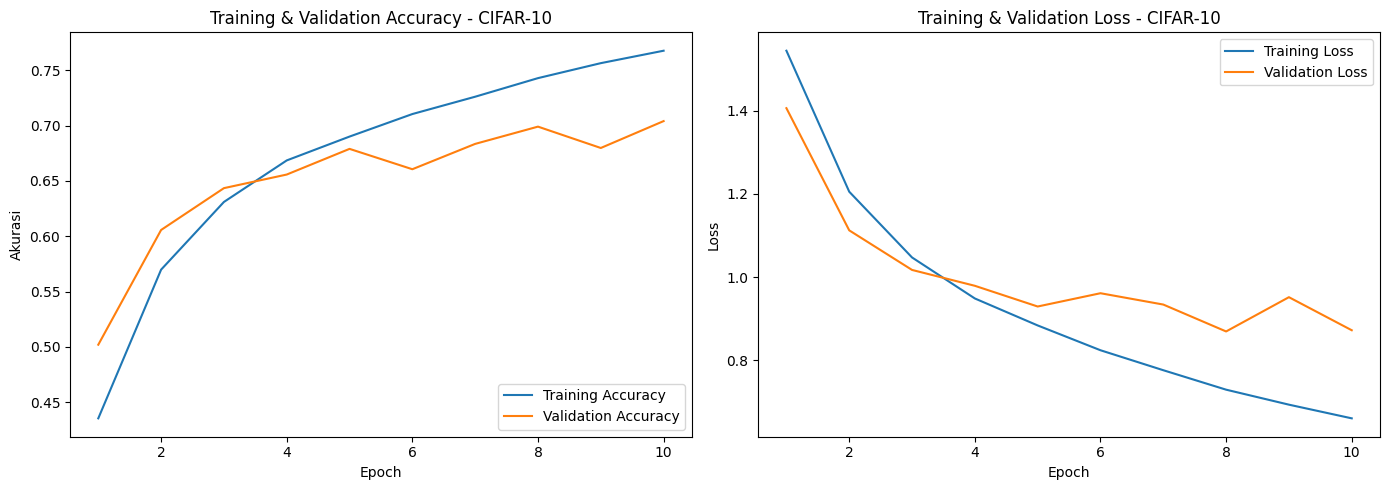

In [30]:
acc_cifar = history_cifar.history['accuracy']
val_acc_cifar = history_cifar.history['val_accuracy']
loss_cifar = history_cifar.history['loss']
val_loss_cifar = history_cifar.history['val_loss']
epochs_range_cifar = range(1, len(acc_cifar) + 1)

plt.figure(figsize=(14, 5))

# Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range_cifar, acc_cifar, label='Training Accuracy')
plt.plot(epochs_range_cifar, val_acc_cifar, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training & Validation Accuracy - CIFAR-10')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range_cifar, loss_cifar, label='Training Loss')
plt.plot(epochs_range_cifar, val_loss_cifar, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training & Validation Loss - CIFAR-10')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()

### 7. Evaluasi Model CIFAR-10 & Visualisasi Prediksi

Kita akan memprediksi seluruh data uji (`test_images`), kemudian menampilkan Confusion Matrix 10 kelas dan menampilkan 5 sampel gambar beserta hasil prediksi aktual dari model.

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.7041 - loss: 0.8726

CIFAR-10 Test Accuracy: 0.7041
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step


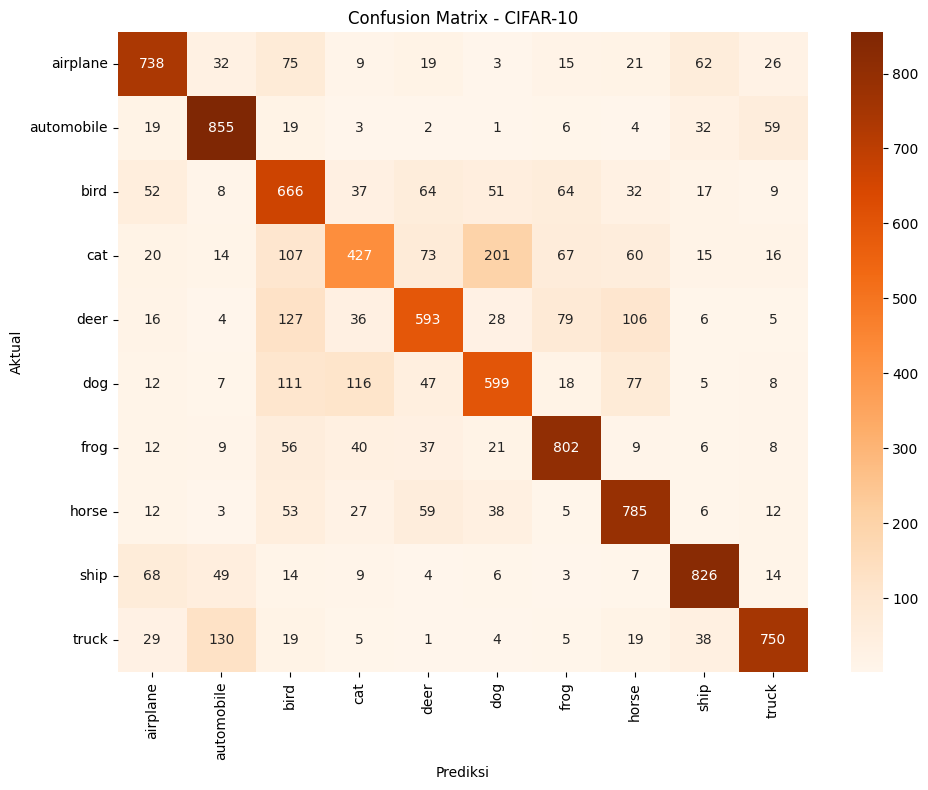


Classification Report CIFAR-10:
              precision    recall  f1-score   support

    airplane       0.75      0.74      0.75      1000
  automobile       0.77      0.85      0.81      1000
        bird       0.53      0.67      0.59      1000
         cat       0.60      0.43      0.50      1000
        deer       0.66      0.59      0.62      1000
         dog       0.63      0.60      0.61      1000
        frog       0.75      0.80      0.78      1000
       horse       0.70      0.79      0.74      1000
        ship       0.82      0.83      0.82      1000
       truck       0.83      0.75      0.79      1000

    accuracy                           0.70     10000
   macro avg       0.70      0.70      0.70     10000
weighted avg       0.70      0.70      0.70     10000



In [31]:
# Evaluasi model
test_loss_cifar, test_acc_cifar = model_cifar.evaluate(test_images, test_labels, verbose=1)
print(f"\nCIFAR-10 Test Accuracy: {test_acc_cifar:.4f}")

# Dapatkan prediksi mentah (logits)
logits_pred = model_cifar.predict(test_images)
# Mengubah logits ke probabilitas menggunakan Softmax
prob_pred = tf.nn.softmax(logits_pred).numpy()
y_pred_cifar = np.argmax(prob_pred, axis=1)
y_true_cifar = test_labels.flatten()

# Confusion Matrix
cm_cifar = confusion_matrix(y_true_cifar, y_pred_cifar)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_cifar, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - CIFAR-10')
plt.tight_layout()
plt.show()

# Classification report
print("\nClassification Report CIFAR-10:")
print(classification_report(y_true_cifar, y_pred_cifar, target_names=class_names))

Mari kita tampilkan visualisasi acak beberapa gambar uji beserta label asli, label hasil prediksi model, dan persentase probabilitas keyakinannya.

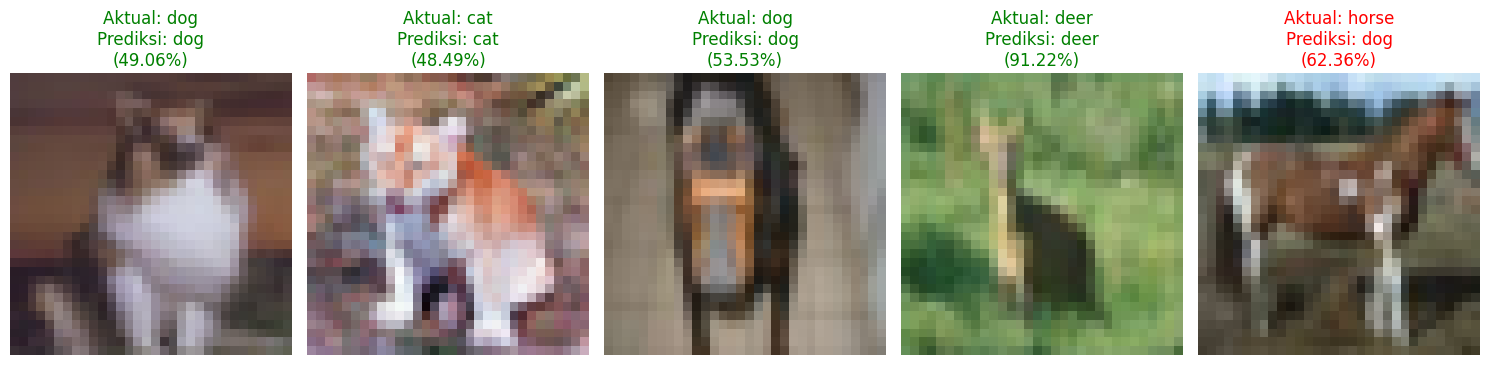

In [32]:
plt.figure(figsize=(15, 6))
random_indices = random.sample(range(len(test_images)), 5)

for idx, rand_id in enumerate(random_indices):
    plt.subplot(1, 5, idx + 1)
    plt.imshow(test_images[rand_id])

    actual_lbl = class_names[y_true_cifar[rand_id]]
    pred_lbl = class_names[y_pred_cifar[rand_id]]
    confidence = prob_pred[rand_id][y_pred_cifar[rand_id]]

    color = 'green' if actual_lbl == pred_lbl else 'red'
    plt.title(f"Aktual: {actual_lbl}\nPrediksi: {pred_lbl}\n({confidence:.2%})", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

### 4. Pembuatan Arsitektur Model CNN CIFAR-10

Kita membuat model Sequential baru dengan arsitektur yang lebih dalam karena dataset CIFAR-10 memiliki variabilitas yang jauh lebih kompleks dibandingkan klasifikasi biner.

In [33]:
model_cifar = models.Sequential([
    # --- Convolutional Block ---
    # Conv 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),

    # Conv 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv 3
    layers.Conv2D(64, (3, 3), activation='relu'),

    # --- Fully Connected Block ---
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)  # Output berjumlah 10 kelas (logits = True)
])

# Compile model
model_cifar.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Menampilkan ringkasan arsitektur model
model_cifar.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

### 5. Pelatihan Model (Training) CIFAR-10

Kita akan melatih model selama 10 epoch dengan menggunakan data validasi yang berasal langsung dari data testing (`test_images` dan `test_labels`) sesuai dengan petunjuk jobsheet.

In [34]:
import time

start_time_cifar = time.perf_counter()

history_cifar = model_cifar.fit(
    train_images,
    train_labels,
    epochs=10,
    validation_data=(test_images, test_labels)
)

end_time_cifar = time.perf_counter()
total_training_time_cifar = end_time_cifar - start_time_cifar
print(f"\nTotal Waktu Training CIFAR-10: {total_training_time_cifar:.2f} detik ({total_training_time_cifar/60:.2f} menit)")

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 105s 67ms/step - accuracy: 0.4614 - loss: 1.4847 - val_accuracy: 0.5561 - val_loss: 1.2266
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 103s 66ms/step - accuracy: 0.5952 - loss: 1.1357 - val_accuracy: 0.6127 - val_loss: 1.1008
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 106s 68ms/step - accuracy: 0.6522 - loss: 0.9889 - val_accuracy: 0.6571 - val_loss: 0.9764
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 104s 67ms/step - accuracy: 0.6863 - loss: 0.8896 - val_accuracy: 0.6792 - val_loss: 0.9270
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 106s 68ms/step - accuracy: 0.7134 - loss: 0.8188 - val_accuracy: 0.6854 - val_loss: 0.9136
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 141s 67ms/step - accuracy: 0.7329 - loss: 0.7572 - val_accuracy: 0.6882 - val_loss: 0.8941
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 102s 65ms/step - accuracy: 0.7526 - loss: 0.7097 - val_accuracy: 0.7022 - val_loss: 0.8746
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 143s 66ms/step - accuracy: 

### 6. Visualisasi Hasil Training CIFAR-10

Berikut grafik performa model CIFAR-10 selama 10 epoch pelatihan.

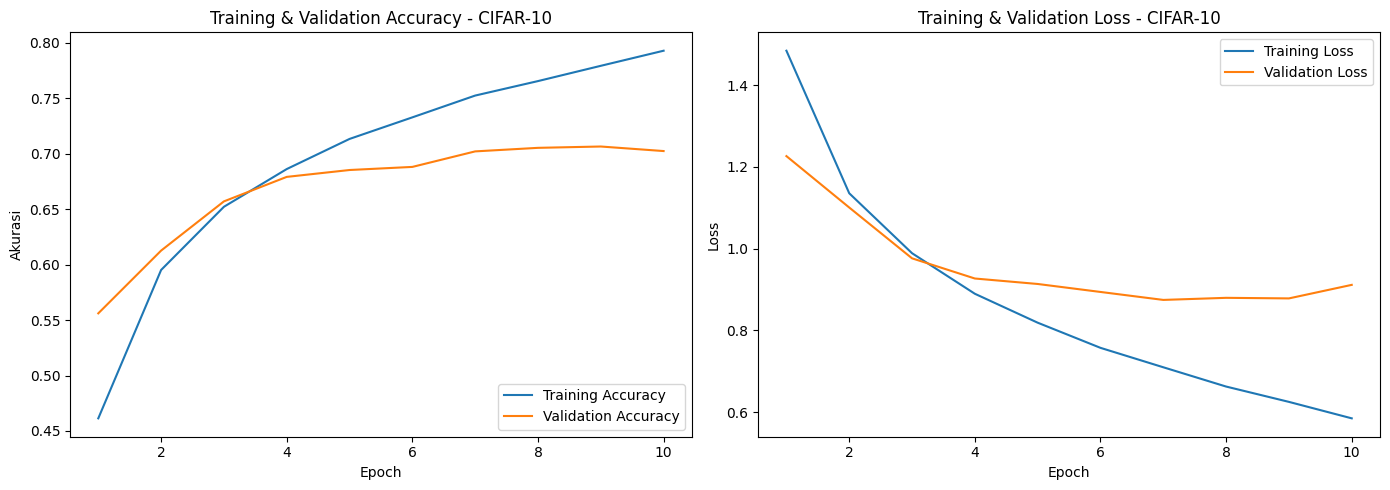

In [35]:
acc_cifar = history_cifar.history['accuracy']
val_acc_cifar = history_cifar.history['val_accuracy']
loss_cifar = history_cifar.history['loss']
val_loss_cifar = history_cifar.history['val_loss']
epochs_range_cifar = range(1, len(acc_cifar) + 1)

plt.figure(figsize=(14, 5))

# Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range_cifar, acc_cifar, label='Training Accuracy')
plt.plot(epochs_range_cifar, val_acc_cifar, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training & Validation Accuracy - CIFAR-10')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range_cifar, loss_cifar, label='Training Loss')
plt.plot(epochs_range_cifar, val_loss_cifar, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training & Validation Loss - CIFAR-10')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.tight_layout()
plt.show()

### 4. Pembuatan Arsitektur Model CNN CIFAR-10

Kita membuat model Sequential baru dengan arsitektur yang lebih dalam karena dataset CIFAR-10 memiliki variabilitas yang jauh lebih kompleks dibandingkan klasifikasi biner.

In [36]:
model_cifar = models.Sequential([
    # --- Convolutional Block ---
    # Conv 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),

    # Conv 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv 3
    layers.Conv2D(64, (3, 3), activation='relu'),

    # --- Fully Connected Block ---
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)  # Output berjumlah 10 kelas (logits = True)
])

# Compile model
model_cifar.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Menampilkan ringkasan arsitektur model
model_cifar.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

### 4. Pembuatan Arsitektur Model CNN CIFAR-10

Kita membuat model Sequential baru dengan arsitektur yang lebih dalam karena dataset CIFAR-10 memiliki variabilitas yang jauh lebih kompleks dibandingkan biner klasifikasi.

In [37]:
model_cifar = models.Sequential([
    # --- Convolutional Block ---
    # Conv 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),

    # Conv 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Conv 3
    layers.Conv2D(64, (3, 3), activation='relu'),

    # --- Fully Connected Block ---
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)  # Output berjumlah 10 kelas (logits = True)
])

# Compile model
model_cifar.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Menampilkan ringkasan arsitektur model
model_cifar.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

### 7. Evaluasi Model Cat vs Dog

Kita akan melakukan prediksi pada seluruh data testing untuk mengevaluasi metrics seperti akurasi keseluruhan, precision, recall, dan F1-score, serta menggambar matriks konfusi (Confusion Matrix).

63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step - accuracy: 0.5320 - loss: 0.6911

Test Loss: 0.6911
Test Accuracy: 0.5320
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step


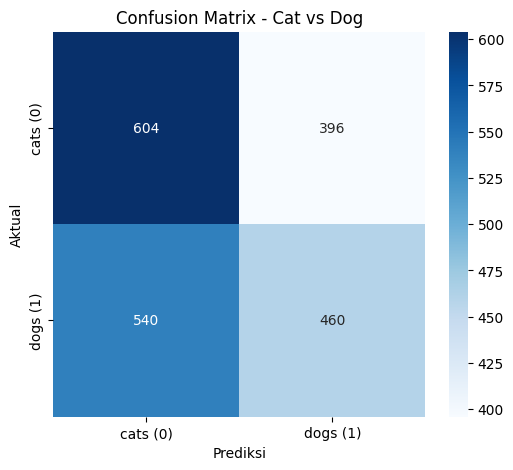


Classification Report:
              precision    recall  f1-score   support

        cats       0.53      0.60      0.56      1000
        dogs       0.54      0.46      0.50      1000

    accuracy                           0.53      2000
   macro avg       0.53      0.53      0.53      2000
weighted avg       0.53      0.53      0.53      2000



In [17]:
# Melakukan evaluasi model pada test set
test_loss, test_acc = model_cat_dog.evaluate(test_set, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

# Reset test generator untuk menghindari ketidaksinkronan urutan
test_set.reset()
predictions = model_cat_dog.predict(test_set)

# Karena aktivasi akhir output adalah Sigmoid (skalar biner),
# kita konversikan probabilitas > 0.5 menjadi kelas 1 (dogs), sisanya 0 (cats)
y_pred = (predictions > 0.5).astype(int).flatten()
y_true = test_set.classes

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['cats (0)', 'dogs (1)'],
            yticklabels=['cats (0)', 'dogs (1)'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - Cat vs Dog')
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['cats', 'dogs']))

### 8. Prediksi Satu Gambar (Single Prediction)

Kita akan memprediksi gambar yang berada di folder `single_prediction` sesuai dengan langkah-langkah yang diinstruksikan oleh dosen.

Gambar untuk prediksi: ['cat_or_dog_2.jpg', 'cat_or_dog_1.jpg']

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


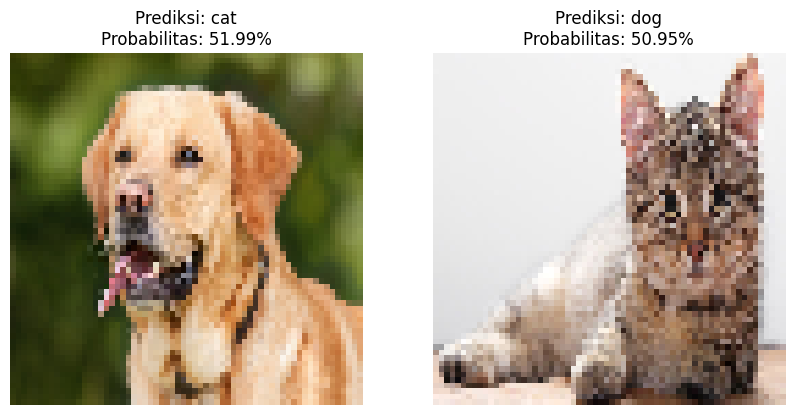

In [18]:
import numpy as np
from tensorflow.keras.preprocessing import image

single_pred_dir = os.path.join(base_dir, 'single_prediction')

if os.path.exists(single_pred_dir):
    files = [f for f in os.listdir(single_pred_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    print(f"Gambar untuk prediksi: {files}\n")

    plt.figure(figsize=(10, 5))
    for i, file_name in enumerate(sorted(files)):
        img_path = os.path.join(single_pred_dir, file_name)

        # 1. Membaca gambar & mengubah ukuran menjadi 64x64
        test_image = image.load_img(img_path, target_size=(64, 64))

        # 2. Mengubah gambar menjadi array
        img_array = image.img_to_array(test_image)

        # 3. Normalisasi piksel ke rentang 0-1
        img_array = img_array / 255.0

        # 4. Menambahkan dimensi batch menggunakan expand_dims
        img_array = np.expand_dims(img_array, axis=0)

        # 5. Melakukan prediksi
        pred_prob = model_cat_dog.predict(img_array)[0][0]

        # Mengubah hasil prediksi menjadi label berdasarkan class_indices
        # Indeks 0: cats, Indeks 1: dogs
        if pred_prob > 0.5:
            prediction_label = 'dog'
            confidence = pred_prob
        else:
            prediction_label = 'cat'
            confidence = 1.0 - pred_prob

        # Tampilkan gambar
        plt.subplot(1, len(files), i+1)
        plt.imshow(test_image)
        plt.title(f"Prediksi: {prediction_label}\nProbabilitas: {confidence:.2%}")
        plt.axis('off')
    plt.show()
else:
    print("Folder single_prediction tidak ditemukan!")

### 7. Evaluasi Model Cat vs Dog

Kita akan melakukan prediksi pada seluruh data testing untuk mengevaluasi metrics seperti akurasi keseluruhan, precision, recall, dan F1-score, serta menggambar matriks konfusi (Confusion Matrix).

63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 145ms/step - accuracy: 0.5320 - loss: 0.6911

Test Loss: 0.6911
Test Accuracy: 0.5320
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step


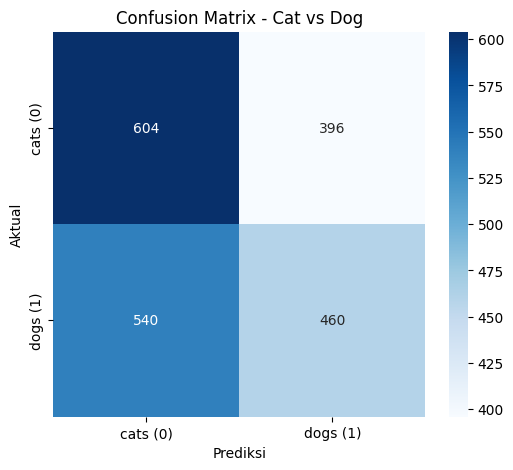


Classification Report:
              precision    recall  f1-score   support

        cats       0.53      0.60      0.56      1000
        dogs       0.54      0.46      0.50      1000

    accuracy                           0.53      2000
   macro avg       0.53      0.53      0.53      2000
weighted avg       0.53      0.53      0.53      2000



In [19]:
# Melakukan evaluasi model pada test set
test_loss, test_acc = model_cat_dog.evaluate(test_set, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

# Reset test generator untuk menghindari ketidaksinkronan urutan
test_set.reset()
predictions = model_cat_dog.predict(test_set)

# Karena aktivasi akhir output adalah Sigmoid (skalar biner),
# kita konversikan probabilitas > 0.5 menjadi kelas 1 (dogs), sisanya 0 (cats)
y_pred = (predictions > 0.5).astype(int).flatten()
y_true = test_set.classes

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['cats (0)', 'dogs (1)'],
            yticklabels=['cats (0)', 'dogs (1)'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - Cat vs Dog')
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['cats', 'dogs']))

### 8. Prediksi Satu Gambar (Single Prediction)

Kita akan memprediksi gambar yang berada di folder `single_prediction` sesuai dengan langkah-langkah yang diinstruksikan oleh dosen.

Gambar untuk prediksi: ['cat_or_dog_2.jpg', 'cat_or_dog_1.jpg']

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


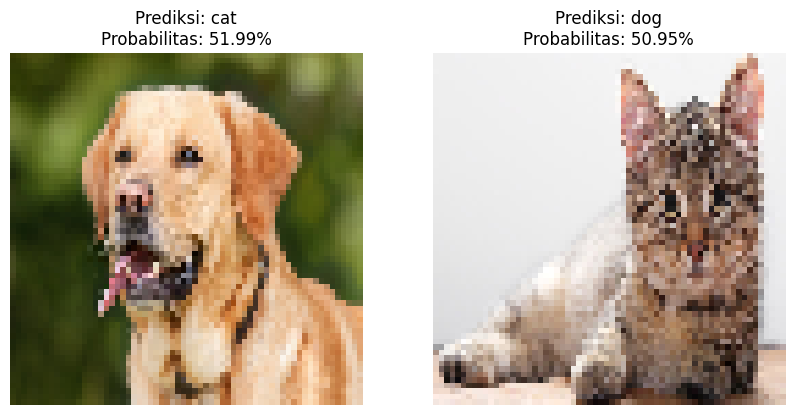

In [20]:
import numpy as np
from tensorflow.keras.preprocessing import image

single_pred_dir = os.path.join(base_dir, 'single_prediction')

if os.path.exists(single_pred_dir):
    files = [f for f in os.listdir(single_pred_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    print(f"Gambar untuk prediksi: {files}\n")

    plt.figure(figsize=(10, 5))
    for i, file_name in enumerate(sorted(files)):
        img_path = os.path.join(single_pred_dir, file_name)

        # 1. Membaca gambar & mengubah ukuran menjadi 64x64
        test_image = image.load_img(img_path, target_size=(64, 64))

        # 2. Mengubah gambar menjadi array
        img_array = image.img_to_array(test_image)

        # 3. Normalisasi piksel ke rentang 0-1
        img_array = img_array / 255.0

        # 4. Menambahkan dimensi batch menggunakan expand_dims
        img_array = np.expand_dims(img_array, axis=0)

        # 5. Melakukan prediksi
        pred_prob = model_cat_dog.predict(img_array)[0][0]

        # Mengubah hasil prediksi menjadi label berdasarkan class_indices
        # Indeks 0: cats, Indeks 1: dogs
        if pred_prob > 0.5:
            prediction_label = 'dog'
            confidence = pred_prob
        else:
            prediction_label = 'cat'
            confidence = 1 - pred_prob

        # Tampilkan gambar
        plt.subplot(1, len(files), i+1)
        plt.imshow(test_image)
        plt.title(f"Prediksi: {prediction_label}\nProbabilitas: {confidence:.2%}")
        plt.axis('off')
    plt.show()
else:
    print("Folder single_prediction tidak ditemukan!")

### 4. Pembuatan Arsitektur Model CNN (Cat vs Dog)

Kita membuat model Sequential dengan menyusun layer demi layer sesuai dengan instruksi yang diberikan.

In [10]:
# Membangun model CNN Sequential
model_cat_dog = models.Sequential([
    # 1. Convolutional Layer 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    # 2. Pooling Layer 1
    layers.MaxPooling2D(pool_size=(2, 2), strides=2),

    # 3. Convolutional Layer 2
    layers.Conv2D(32, (3, 3), activation='relu'),
    # 4. Pooling Layer 2
    layers.MaxPooling2D(pool_size=(2, 2), strides=2),

    # 5. Flattening
    layers.Flatten(),

    # 6. Dense Layer (Fully Connected Layer)
    layers.Dense(units=128, activation='relu'),

    # 7. Output Layer (Sigmoid untuk klasifikasi biner)
    layers.Dense(units=1, activation='sigmoid')
])

# Compile model
model_cat_dog.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Menampilkan ringkasan arsitektur model
model_cat_dog.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)